# 01 · Domain shift: pad handwriting is not MNIST

The game's model was trained on MNIST (scanned pen-on-paper digits), but in the game the
player writes with a mouse, finger or stylus on the talisman pad. Before the model sees
anything, the strokes go through two steps in the browser:

1. `js/ui/pad.js` `renderForModel()` redraws the raw polylines white-on-black on a 280×280
   canvas, longest side 190 px, with a round pen of **fixed width 18 px**;
2. `js/ai/processing.js` `preprocessToMNIST()` thresholds (Otsu), crops all foreground,
   scales the longest side to 20 px (nearest neighbour), pastes into 28×28 and centres the
   mass.

This notebook
- checks that the Python port (`browser.py`) reproduces the browser exactly,
- builds the test sets used by the other notebooks,
- measures how different "pad-like" input is from MNIST.

**Test sets** (all go through the same browser pipeline as the game):

| name | what | why |
|---|---|---|
| `mnist` | MNIST test set as is | the number everyone reports |
| `mnist_pipe` | MNIST test, upscaled to 280×280 and preprocessed like the browser | effect of the preprocessing alone |
| `pad_skel` | MNIST test digits thinned to a skeleton and redrawn with the pad's pen (+ small affine/elastic jitter) | same shapes as MNIST, game rendering |
| `pad_tmpl` | hand-made stroke templates (2–3 styles per digit), 200 synthetic writers | shapes MNIST never saw; closest stand-in for real players |
| `real` | samples drawn in `collect/index.html` | the ground truth, once collected |

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

import datasets, synth
from browser import strokes_to_28, render_strokes, shift_image

plt.rcParams['figure.dpi'] = 80
x_train, y_train, x_test, y_test = datasets.load_mnist()
print(x_train.shape, x_test.shape)

(60000, 28, 28) (10000, 28, 28)


## 1. Does the Python port match the browser?

`collect/samples/pipeline_check.json` holds 22 digits drawn in the collector page with scripted
pointer events. For each, the page stored the raw strokes **and** the 28×28 image produced by
the game's own `processing.js`. We re-render the strokes in Python and compare.

samples: 22
median L1 distance (sum over 784 px): 1.30   median flipped pixels: 2
samples where the centring step differs by 1 px: 2


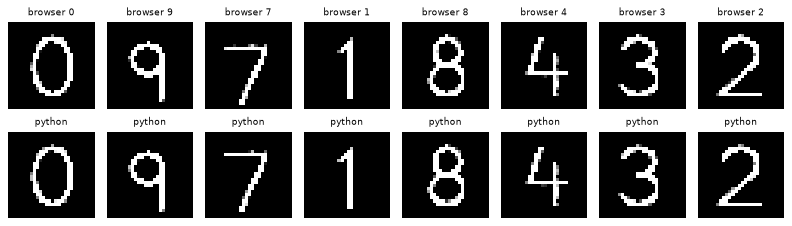

In [2]:
check = json.loads((datasets.SAMPLES / 'pipeline_check.json').read_text())
l1, flips, shifted = [], [], 0
for s in check:
    a = np.array(s['img28'], np.float32).reshape(28, 28)
    b = strokes_to_28([np.array(t) for t in s['strokes']], s['pad'])
    l1.append(np.abs(a - b).sum())
    flips.append(((a > 0.5) != (b > 0.5)).sum())
    best = min((np.abs(a - shift_image(b, dx, dy)).sum(), dx, dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1))
    shifted += best[1:] != (0, 0)
print(f'samples: {len(check)}')
print(f'median L1 distance (sum over 784 px): {np.median(l1):.2f}   median flipped pixels: {np.median(flips):.0f}')
print(f'samples where the centring step differs by 1 px: {shifted}')

fig, ax = plt.subplots(2, 8, figsize=(10, 3))
for i in range(8):
    s = check[i]
    ax[0, i].imshow(np.array(s['img28']).reshape(28, 28), cmap='gray'); ax[0, i].set_title(f"browser {s['label']}", fontsize=8)
    ax[1, i].imshow(strokes_to_28([np.array(t) for t in s['strokes']], s['pad']), cmap='gray'); ax[1, i].set_title('python', fontsize=8)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

The port is pixel-close: the only real differences are anti-aliasing at stroke edges
(canvas vs. a supersampled PIL render) and, in a few samples, the centre-of-mass rounding
landing on the other side of .5 (a 1-pixel shift). Good enough to trust the numbers below.

## 2. Build the datasets (cached in `cache/`)

In [3]:
x_mnist_pipe = datasets.mnist_through_pipeline(x_test, 'mnist_test_pipe')
x_skel, y_skel = datasets.pad_skeleton_set(x_test, y_test, 'pad_skel_test', seed=2)
x_tmpl, y_tmpl, w_tmpl = datasets.template_set(200, 5, 'pad_tmpl_test', seed=10)
# training material for notebook 03 (MNIST *train* digits redrawn with the pad pen)
x_skel_tr, y_skel_tr = datasets.pad_skeleton_set(x_train, y_train, 'pad_skel_train', seed=1)
# writers for the personalisation experiment in notebook 04 (never used for training a base model)
x_pw, y_pw, w_pw = datasets.template_set(40, 30, 'pad_tmpl_writers', seed=20)
real = datasets.load_real_samples()
real = [s for s in real if s['writer'] != 'pipeline-check']
print('mnist_pipe', x_mnist_pipe.shape, '| pad_skel', x_skel.shape, '| pad_tmpl', x_tmpl.shape,
      '| skel train', x_skel_tr.shape, '| writers', x_pw.shape, '| real samples', len(real))

mnist_pipe (10000, 28, 28) | pad_skel (10000, 28, 28) | pad_tmpl (10000, 28, 28) | skel train (60000, 28, 28) | writers (12000, 28, 28) | real samples 0


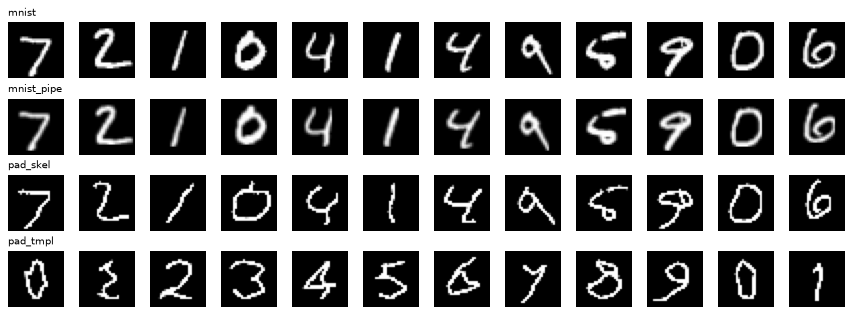

In [4]:
def show_rows(rows, names, n=12):
    fig, ax = plt.subplots(len(rows), n, figsize=(n * 0.9, len(rows) * 1.0))
    for r, (imgs, name) in enumerate(zip(rows, names)):
        for i in range(n):
            ax[r, i].imshow(imgs[i], cmap='gray', vmin=0, vmax=1); ax[r, i].axis('off')
        ax[r, 0].set_title(name, fontsize=9, loc='left')
    plt.tight_layout(); plt.show()

show_rows([x_test / 255, x_mnist_pipe, x_skel, x_tmpl[::5][:12]], ['mnist', 'mnist_pipe', 'pad_skel', 'pad_tmpl'])

## 3. How big is the shift?

Three simple measurements:
- **ink area**: fraction of the 28×28 image that is "ink" (> 0.5),
- **gray pixels**: fraction of non-zero pixels that are neither black nor white (soft edges),
- **domain classifier**: can a plain logistic regression on raw pixels tell the two sources
  apart? 50% = indistinguishable, 100% = completely different distributions.

In [5]:
def stats(x):
    x = x.reshape(len(x), -1)
    ink = (x > 0.5).mean(1)
    nz = x > 0.02
    gray = ((x > 0.02) & (x < 0.98)).sum(1) / np.maximum(nz.sum(1), 1)
    return ink.mean(), gray.mean()

def domain_acc(a, b, n=3000, seed=0):
    rng = np.random.default_rng(seed)
    a = a[rng.choice(len(a), n, replace=False)].reshape(n, -1)
    b = b[rng.choice(len(b), n, replace=False)].reshape(n, -1)
    X, y = np.concatenate([a, b]), np.r_[np.zeros(n), np.ones(n)]
    return cross_val_score(LogisticRegression(max_iter=300, C=0.1), X, y, cv=3).mean()

mn = x_test.astype(np.float32) / 255
rows = []
for name, x in [('mnist', mn), ('mnist_pipe', x_mnist_pipe), ('pad_skel', x_skel), ('pad_tmpl', x_tmpl)]:
    ink, gray = stats(x)
    dom = domain_acc(mn, x) if name != 'mnist' else 0.5
    rows.append((name, ink, gray, dom))
    print(f'{name:11s} ink area {ink:6.1%}   gray pixels {gray:6.1%}   MNIST-vs-this classifier {dom:6.1%}')

mnist       ink area  13.4%   gray pixels  61.5%   MNIST-vs-this classifier  50.0%


mnist_pipe  ink area  12.8%   gray pixels  86.6%   MNIST-vs-this classifier  57.4%


pad_skel    ink area   9.1%   gray pixels  11.5%   MNIST-vs-this classifier  79.5%


pad_tmpl    ink area   9.2%   gray pixels  11.2%   MNIST-vs-this classifier  87.0%


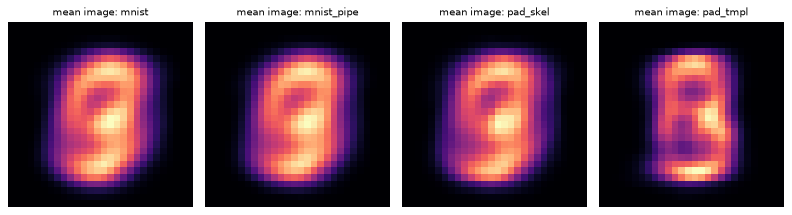

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
for a, (name, x) in zip(ax, [('mnist', mn), ('mnist_pipe', x_mnist_pipe), ('pad_skel', x_skel), ('pad_tmpl', x_tmpl)]):
    a.imshow(x.mean(0), cmap='magma'); a.set_title(f'mean image: {name}', fontsize=9); a.axis('off')
plt.tight_layout(); plt.show()

## 4. Real samples

Open `collect/index.html` through any static server **from the repository root** (it imports
the game's `js/ai/processing.js`), e.g. `python -m http.server` and then
`http://localhost:8000/mlp_training/research/collect/`. Write ~20 samples per digit
(≈ 200 in total, about 10 minutes), press *Download JSON*, and drop the file into
`collect/samples/`. Every notebook picks the files up automatically and reports a `real` column;
the 2- and 3-digit modes feed notebook 05.

In [7]:
if real:
    from collections import Counter
    print(Counter(s['label'] for s in real), Counter(s['device'] for s in real))
    show_rows([np.stack([s['img28'] for s in real[:12]])], ['real'])
else:
    print('No real samples yet: the "real" column is skipped in the following notebooks.')

No real samples yet: the "real" column is skipped in the following notebooks.


## 小结

- Python 版 `browser.py` 与浏览器的 `processing.js` 几乎逐像素一致（仅抗锯齿边缘和偶发的 1 像素质心取整差异），
  因此后面 notebook 里的数字可以直接代表游戏里的表现。
- 游戏输入与 MNIST 的差异非常明显：`pad.js` 用固定 18px 笔宽（相对 190px 字高）重绘笔画，
  预处理后在 28×28 上笔画只有约 2px 宽、几乎是二值图；MNIST 笔画更粗、边缘是灰度渐变。
  量化：pad 风格图片的灰度像素占比只有约 11%（MNIST 约 62%），墨迹面积 9% vs 13%；
  一个最简单的线性"域分类器"能以 80–87% 的准确率区分 MNIST 与 pad 风格图片（50% 表示无法区分）——
  这就是 domain shift。仅仅把 MNIST 走一遍浏览器预处理（`mnist_pipe`，57.5%）几乎不产生偏移，
  偏移主要来自"细而均匀的笔画 + 不同的书写字形"。
- 我们构建了两个合成的 pad 风格测试集：`pad_skel`（MNIST 字形 + 游戏渲染）和 `pad_tmpl`
  （手工笔画模板 + 200 个模拟书写者，字形 MNIST 没见过）。真实样本可用 `collect/index.html` 采集。